In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

In [2]:
df=pd.read_excel("Sharktank_india.xlsx")

In [3]:
df.head()

,episode_number,pitch_number,brand_name,idea,deal,pitcher_ask_amount,ask_equity,ask_valuation,deal_amount,deal_equity,...,ashneer_deal,anupam_deal,aman_deal,namita_deal,vineeta_deal,peyush_deal,ghazal_deal,total_sharks_invested,amount_per_shark,equity_per_shark
0,1,1,BluePine Industries,Frozen Momos,1.0,50.0,5.0,1000.00,75.0,16.00,...,1,0,1,0,1,0,0,3,25.0,5.333333
1,1,2,Booz scooters,Renting e-bike for mobility in private spaces,NaN,40.0,15.0,266.67,40.0,50.00,...,1,0,0,0,1,0,0,2,20.0,25
2,1,3,Heart up my Sleeves,Detachable Sleeves,1.0,25.0,10.0,250.00,25.0,30.00,...,0,1,0,0,1,0,0,2,12.5,
3,2,4,Tagz Foods,Healthy Potato Chips,1.0,70.0,1.0,7000.00,70.0,2.75,...,1,0,0,0,0,0,0,1,70.0,2.75
4,2,5,Head and Heart,Brain Development Course,0.0,50.0,5.0,1000.00,0.0,0.00,...,0,0,0,0,0,0,0,0,0.0,0


In [4]:
df.columns

Index(['episode_number', 'pitch_number', 'brand_name', 'idea', 'deal',
       'pitcher_ask_amount', 'ask_equity', 'ask_valuation', 'deal_amount',
       'deal_equity', 'deal_valuation', 'ashneer_present', 'anupam_present',
       'aman_present', 'namita_present', 'vineeta_present', 'peyush_present',
       'ghazal_present', 'ashneer_deal', 'anupam_deal', 'aman_deal',
       'namita_deal', 'vineeta_deal', 'peyush_deal', 'ghazal_deal',
       'total_sharks_invested', 'amount_per_shark', 'equity_per_shark'],
      dtype='object')

In [36]:
df.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
114    False
115    False
116    False
117    False
118    False
Length: 119, dtype: bool

In [37]:
df.isnull().sum()

episode_number           0
pitch_number             0
brand_name               0
idea                     0
deal                     1
pitcher_ask_amount       0
ask_equity               0
ask_valuation            0
deal_amount              0
deal_equity              0
deal_valuation           0
ashneer_present          0
anupam_present           0
aman_present             0
namita_present           0
vineeta_present          0
peyush_present           0
ghazal_present           0
ashneer_deal             0
anupam_deal              0
aman_deal                0
namita_deal              0
vineeta_deal             0
peyush_deal              0
ghazal_deal              0
total_sharks_invested    0
amount_per_shark         0
equity_per_shark         0
dtype: int64

In [38]:
df.dtypes

episode_number             int64
pitch_number               int64
brand_name                object
idea                      object
deal                      object
pitcher_ask_amount       float64
ask_equity               float64
ask_valuation            float64
deal_amount              float64
deal_equity              float64
deal_valuation           float64
ashneer_present            int64
anupam_present             int64
aman_present               int64
namita_present             int64
vineeta_present            int64
peyush_present             int64
ghazal_present             int64
ashneer_deal               int64
anupam_deal                int64
aman_deal                  int64
namita_deal                int64
vineeta_deal               int64
peyush_deal                int64
ghazal_deal                int64
total_sharks_invested      int64
amount_per_shark         float64
equity_per_shark          object
dtype: object

In [7]:
df['deal'] = pd.to_numeric(df['deal'], errors='coerce') # This code converts the values in the deal col. into numeric data types (int./ floats)
df = df.dropna(subset=['deal'])    # This will delete those NaN values
# errors='coerce' is a parameter used in Pandas, particularly with pd.to_numeric(), to convert invalid values into NaN.

In [8]:
df['deal'].dtypes

dtype('float64')

In [9]:
total_pitches=len(df['deal']) # len('deal') = o/p =4, d,e,a,l
total_pitches

117

In [10]:
successful_deals = df['deal'].sum()
successful_deals

np.float64(65.0)

In [11]:
# Percentage of successful deals
deal_percentage = (successful_deals / total_pitches) * 100
print(deal_percentage)

55.55555555555556


In [21]:
# Details

print("Total Pitches:", total_pitches)
print("Successful Deals:", successful_deals)
print(f"Deal Percentage: {deal_percentage.round(2)}%")

Total Pitches: 117
Successful Deals: 65.0
Deal Percentage: 55.56%


In [5]:
# General mean\median

avg_deal_amt=df['deal_amount'].mean()
print(avg_deal_amt)

median_deal_amt=df['deal_amount'].median()
print(median_deal_amt)

32.495807226890754
25.0


In [23]:
# That received investment

avg_deal_amt_inv=df[df['deal'] == 1]['deal_amount'].mean()

median_deal_amt_inv=df[df['deal'] == 1]['deal_amount'].median()

# Output
print("Average Deal Amount:", round(avg_deal_amt_inv, 2))
print("Median Deal Amount:", round(median_deal_amt_inv, 2))

Average Deal Amount: 55.8
Median Deal Amount: 50.0


In [87]:
ashneer_inv = df[df['ashneer_deal']==1].sum()
anupam_inv=df[df['anupam_deal']==1].sum()
aman_inv=df[df['aman_deal']==1].sum()
namita_inv=df[df['namita_deal']==1].sum()
vineeta_inv=df[df['vineeta_deal']==1].sum()
peyush_inv=df[df['peyush_deal']==1].sum()
ghazal_inv=df[df['ghazal_deal']==1].sum()
print(f"Ashneer Investment: {ashneer_inv}\n Aman Deal: {aman_inv}")

TypeError: can only concatenate str (not "float") to str

In [24]:
total_amt_invested=df['deal_amount'].sum().round()
print("Total Investment by all sharks:", round(total_amt_invested, 2))

Total Investment by all sharks: 3727.0


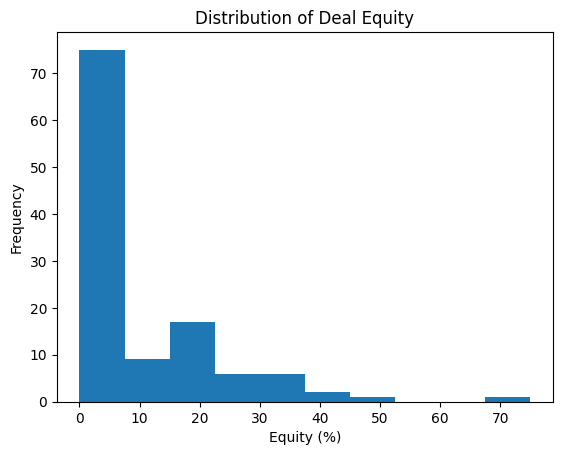

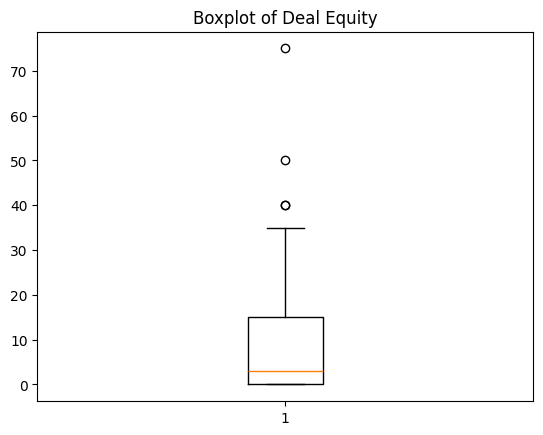

Lower Bound: -22.5
Upper Bound: 37.5
Outliers:
 43    40.0
66    75.0
77    40.0
82    50.0
Name: deal_equity, dtype: float64


In [90]:
# For visualization

plt.figure()
plt.hist(df['deal_equity'], bins=10)
plt.title("Distribution of Deal Equity")
plt.xlabel("Equity (%)")
plt.ylabel("Frequency")
plt.show()

# Boxplot For outliers

plt.figure()
plt.boxplot(df['deal_equity'])
plt.title("Boxplot of Deal Equity")
plt.show()

# Detect outliers (IQR method)

Q1 = df['deal_equity'].quantile(0.25)
Q3 = df['deal_equity'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['deal_equity'] < lower_bound) | (df['deal_equity'] > upper_bound)]  # | means Logical OR operator

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Outliers:\n", outliers['deal_equity'])

In [98]:
correlation= df['ask_valuation'].corr(df['deal_valuation'])
print('Correlation b/w two:', correlation)

Correlation b/w two: 0.027444013391269936


Correlation b/w two: 0.6634843170182724


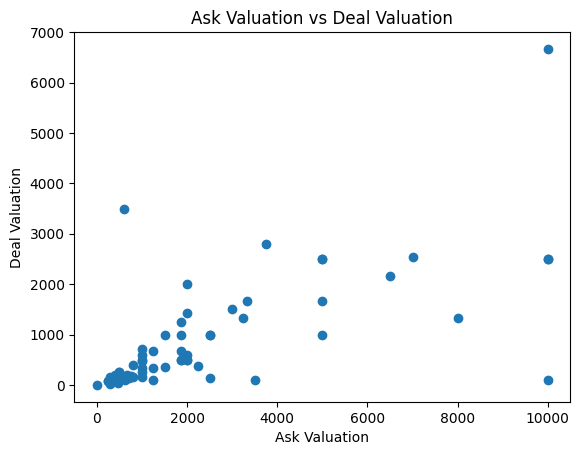

In [25]:
# Now increasing the correlation by removing Nan or 0 values rows
# Remove rows where deal didn't happen (deal_valuation = NaN or 0)

df_new=df[df['deal_valuation']>0] 

correlation_new= df_new['ask_valuation'].corr(df_new['deal_valuation'])
print('Correlation b/w two:', correlation_new)

# Visualization
import matplotlib.pyplot as plt
plt.figure()
plt.scatter(df_new['ask_valuation'], df_new['deal_valuation'])
plt.title("Ask Valuation vs Deal Valuation")
plt.xlabel("Ask Valuation")
plt.ylabel("Deal Valuation")
plt.show()

The value is now 66.34%, means both columns now are highly correlated with each other.

In [109]:
df['deal'] = pd.to_numeric(df['deal'], errors='coerce')

df_new=df[df['deal']==1]
equity_percentage=df_new['deal_equity'].mean()
print("Average Equity Given per Deal:", round(equity_percentage, 2), "%")

Average Equity Given per Deal: 15.6 %


episode_number
1     3.0
10    3.0
27    3.0
21    3.0
17    3.0
16    3.0
15    3.0
13    3.0
8     3.0
33    3.0
9     2.0
24    2.0
3     2.0
28    2.0
4     2.0
20    2.0
25    2.0
26    2.0
12    2.0
11    2.0
30    1.0
29    1.0
32    1.0
31    1.0
34    1.0
18    1.0
23    1.0
22    1.0
19    1.0
2     1.0
14    1.0
7     1.0
6     1.0
5     1.0
35    1.0
Name: deal, dtype: float64


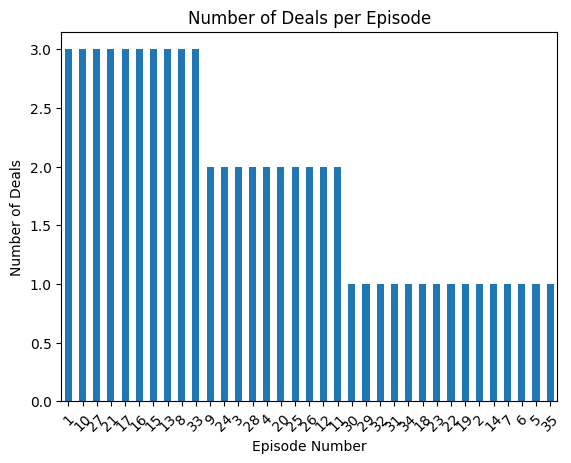

In [115]:
deals_per_episode=df.groupby('episode_number')['deal'].sum().sort_values(ascending=False)
print(deals_per_episode)

# Visualization
plt.figure()
deals_per_episode.plot(kind='bar')
plt.title("Number of Deals per Episode")
plt.xlabel("Episode Number")
plt.ylabel("Number of Deals")
plt.xticks(rotation=45)
plt.show()

In [120]:
# Pitches asking for more than ₹1 crore
cal = df[df['pitcher_ask_amount'] > 100]

# Total pitches asking for more than ₹1 crore
total_pitches = cal.shape[0]  # Gives no. of rows

# Pitches that received investments among these
invested_pitches = cal[cal['deal'] == 1].shape[0]

print("Total pitches:", total_pitches)
print("Pitches received investment:", invested_pitches)

Total pitches: 7
Pitches received investment: 1


In [29]:
ttl_sharks=(df['total_sharks_invested']>1).sum()

# %age of sharks involved
percentage=(ttl_sharks)/len(df)*100

# Output
print("Number of pitches with multiple sharks:", ttl_sharks)
print("Percentage of such pitches:", round(percentage, 2), "%")

Number of pitches with multiple sharks: 42
Percentage of such pitches: 35.9 %


In [30]:
# No of deals both sharks closed

ash=df['ashneer_deal'].sum()
pey=df['peyush_deal'].sum()
print("Deals closed by Ashneer:", ash)
print("Deals closed by Peyush:", pey)

Deals closed by Ashneer: 19
Deals closed by Peyush: 28


Ashneer_amt_invested: 454.33
peyush_amt_invested: 819.67


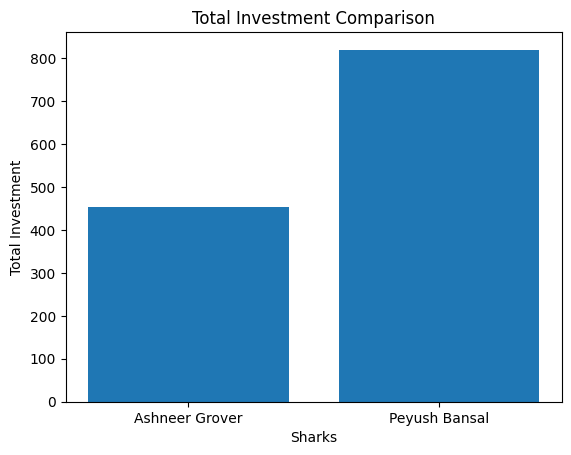

In [31]:
Ash_amt_invested=df[df['ashneer_deal']==1]['amount_per_shark'].sum().round(2)
print("Ashneer_amt_invested:", Ash_amt_invested)

pey_amt_invested=df[df['peyush_deal']==1]['amount_per_shark'].sum().round(2)
print("peyush_amt_invested:", pey_amt_invested)

### Visualization

import matplotlib.pyplot as plt
names = ["Ashneer Grover", "Peyush Bansal"]
values = [Ash_amt_invested, pey_amt_invested]
plt.figure()
plt.bar(names, values)
plt.title("Total Investment Comparison")
plt.xlabel("Sharks")
plt.ylabel("Total Investment")
plt.show()

In [156]:
extra_funding_cases=df[df['deal_amount']>df['pitcher_ask_amount']]

# Count such cases
count_cases = len(extra_funding_cases)
print("Number of cases where deal_amount exceeded ask_amount:", count_cases)

# Show details
print("\nCases:\n")
print(extra_funding_cases[['episode_number', 'brand_name', 'idea', 'pitcher_ask_amount', 'deal_amount']])

Number of cases where deal_amount exceeded ask_amount: 9

Cases:

     episode_number           brand_name                            idea  \
0                 1  BluePine Industries                    Frozen Momos   
37               13                Annie         Braille Literary Device   
39               13      The Yarn Bazaar                Yarn-Trading App   
43               15     Hammer Lifestyle            Smart Audio Products   
59               19              WeSTOCK  Livestock health monitoring AI   
64               20             IN A CAN                   Can Cocktails   
76               24         The Sass Bar                           Gifts   
90               28             Humpy A2           Organic Milk Products   
110              33           Tweek Labs                      Sportswear   

     pitcher_ask_amount  deal_amount  
0                  50.0         75.0  
37                 30.0        105.0  
39                 50.0        100.0  
43               

C:\Users\NitendraSinghChauhan\AppData\Local\Temp\ipykernel_14924\3062673713.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['calc_valuation'] = (df['deal_amount'] / df['deal_equity']) * 100
C:\Users\NitendraSinghChauhan\AppData\Local\Temp\ipykernel_14924\3062673713.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['roi_proxy'] = df['calc_valuation'] / df['deal_amount']


ROI Proxy by Shark:

ashneer    20.360617
aman       16.303055
anupam     12.879093
namita     12.478458
peyush     11.940583
ghazal      9.183673
vineeta     6.488946
dtype: float64


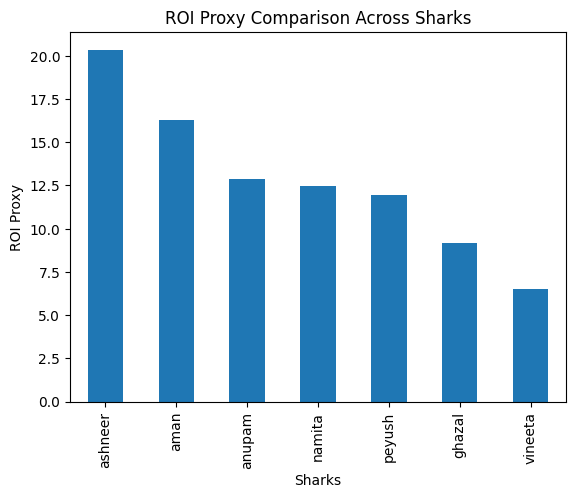

In [157]:
# Remove rows without deals
df = df[df['deal_amount'] > 0]

# Calculate deal valuation (if not present)
df['calc_valuation'] = (df['deal_amount'] / df['deal_equity']) * 100

# ROI proxy
df['roi_proxy'] = df['calc_valuation'] / df['deal_amount']

### STEP 2: Assign ROI per shark

sharks = ['ashneer', 'peyush', 'aman', 'namita', 'vineeta', 'anupam', 'ghazal']

roi_per_shark = {}

for shark in sharks:
    col = f"{shark}_deal"
    if col in df.columns:
        shark_df = df[df[col] == 1]
        roi_per_shark[shark] = shark_df['roi_proxy'].mean()

# Convert to series
roi_series = pd.Series(roi_per_shark).sort_values(ascending=False)

print("ROI Proxy by Shark:\n")
print(roi_series)

### STEP: 3 Visualization

import matplotlib.pyplot as plt
plt.figure()
roi_series.plot(kind='bar')
plt.title("ROI Proxy Comparison Across Sharks")
plt.xlabel("Sharks")
plt.ylabel("ROI Proxy")
plt.show()

episode_number
1     25.333333
2      2.750000
3     10.500000
4     16.250000
5      1.500000
6     20.000000
7      4.000000
8     13.933333
9      8.500000
10    14.333333
11    17.500000
12    19.500000
13    11.000000
14     6.000000
15    23.333333
16    10.166667
17    20.000000
18     1.000000
19    10.000000
20     6.500000
21    38.000000
22     4.000000
23    10.000000
24    37.500000
25    10.500000
26    26.500000
27     4.000000
28    22.500000
29    21.000000
30     6.000000
31     2.680000
32     2.000000
33    15.000000
34    20.000000
35    30.000000
Name: deal_equity, dtype: float64


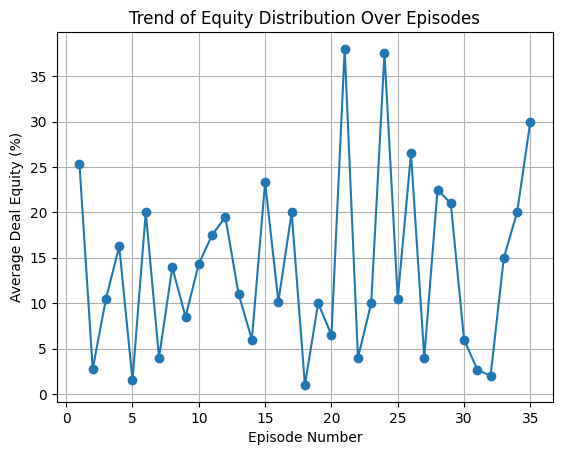

In [158]:
# Keep only valid deals
df_clean = df[df['deal_equity'] > 0]

# Average equity per episode
equity_trend = df_clean.groupby('episode_number')['deal_equity'].mean()
print(equity_trend)

# step 2: Visualization

plt.figure()
plt.plot(equity_trend.index, equity_trend.values, marker='o')
plt.title("Trend of Equity Distribution Over Episodes")
plt.xlabel("Episode Number")
plt.ylabel("Average Deal Equity (%)")
plt.grid()
plt.show()

Correlation: 0.679


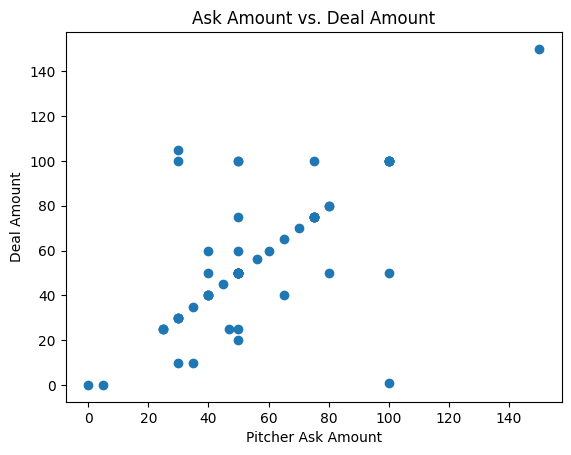

C:\Users\NitendraSinghChauhan\AppData\Local\Temp\ipykernel_14924\2760715359.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['ask_category'] = pd.cut(
C:\Users\NitendraSinghChauhan\AppData\Local\Temp\ipykernel_14924\2760715359.py:28: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  success_rate = df.groupby('ask_category')['deal'].mean() * 100


ask_category
Low       100.000000
Medium     95.833333
High      100.000000
Name: deal, dtype: float64


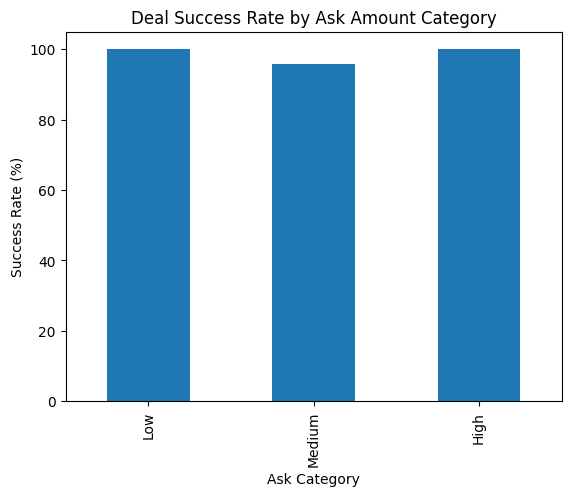

In [164]:
## Relationship (Correlation + scatter plot)

# Only consider rows where deal happened
df_deals = df[df['deal'] == 1]

# Correlation
correlation = df_deals['pitcher_ask_amount'].corr(df_deals['deal_amount'])
print("Correlation:", round(correlation, 3))

# Scatter plot
plt.figure()
plt.scatter(df_deals['pitcher_ask_amount'], df_deals['deal_amount'])
plt.title("Ask Amount vs. Deal Amount")
plt.xlabel("Pitcher Ask Amount")
plt.ylabel("Deal Amount")
plt.show()

### Part B: 

# Create bins
df['ask_category'] = pd.cut(
    df['pitcher_ask_amount'],
    bins=3,
    labels=['Low', 'Medium', 'High']
)

# Deal success rate by category
success_rate = df.groupby('ask_category')['deal'].mean() * 100
print(success_rate)

## Visualization

plt.figure()
success_rate.plot(kind='bar')
plt.title("Deal Success Rate by Ask Amount Category")
plt.xlabel("Ask Category")
plt.ylabel("Success Rate (%)")
plt.show()

                deal  deal_amount
episode_number                   
17               3.0    280.00000
13               3.0    255.00000
27               3.0    200.00101
16               3.0    170.00000
21               3.0    160.00000
28               2.0    150.00000
25               2.0    150.00000
20               2.0    140.00000
8                3.0    136.00000
15               3.0    125.00005
1                3.0    125.00000
4                2.0    125.00000
12               2.0    115.00000
26               2.0    115.00000
33               3.0    110.00000
9                2.0    100.00000
7                0.0    100.00000
14               1.0    100.00000
5                1.0    100.00000
3                2.0     95.00000
10               3.0     85.00000
11               2.0     80.00000
30               1.0     80.00000
29               1.0     75.00000
31               1.0     75.00000
2                1.0     70.00000
19               1.0     60.00000
22            

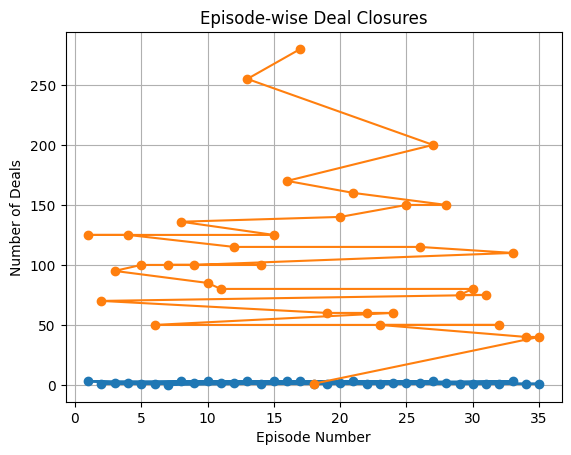

In [173]:
episode_wise_deal=df.groupby('episode_number')[['deal', 'deal_amount']].sum().sort_values(by='deal_amount', ascending=False)
print(episode_wise_deal)

## visualization
plt.figure()
plt.plot(episode_wise_deal.index, episode_wise_deal.values, marker='o')
plt.title("Episode-wise Deal Closures")
plt.xlabel("Episode Number")
plt.ylabel("Number of Deals")
plt.grid()
plt.show()

Correlation between Ask Equity and Deal Valuation: -0.527


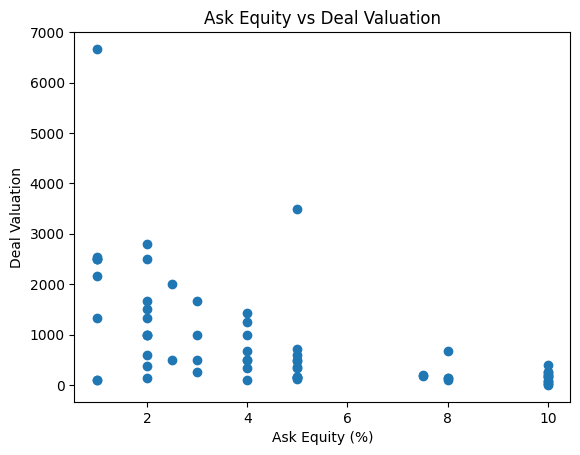

equity_category
Low Equity (<10%)    882.623906
Medium (10–20%)             NaN
High (>20%)                 NaN
Name: deal_valuation, dtype: float64


C:\Users\NitendraSinghChauhan\AppData\Local\Temp\ipykernel_14924\942432117.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_new['equity_category'] = pd.cut(
C:\Users\NitendraSinghChauhan\AppData\Local\Temp\ipykernel_14924\942432117.py:27: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  valuation_by_equity = df_new.groupby('equity_category')['deal_valuation'].mean()


In [175]:
# Keep only rows where deal happened
df_new = df[df['deal_valuation'] > 0]

## step 2: Correlation analysis

correlation = df_new['ask_equity'].corr(df_new['deal_valuation'])
print("Correlation between Ask Equity and Deal Valuation:", round(correlation, 3))

## step 3 : Visualization

plt.figure()
plt.scatter(df_new['ask_equity'], df_new['deal_valuation'])
plt.title("Ask Equity vs Deal Valuation")
plt.xlabel("Ask Equity (%)")
plt.ylabel("Deal Valuation")
plt.show()

## step 4:  Group based analysis(stronger insight)
# Create equity categories
df_new['equity_category'] = pd.cut(
    df_new['ask_equity'],
    bins=[0, 10, 20, 100],
    labels=['Low Equity (<10%)', 'Medium (10–20%)', 'High (>20%)']
)

# Average valuation per category
valuation_by_equity = df_new.groupby('equity_category')['deal_valuation'].mean()
print(valuation_by_equity)